In [1]:
import pandas as pd
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv('str14_OPEK_neft_usl.csv', delimiter=';')

In [3]:
df

,n,x1,x2,y
0,1,"6,511","0,5014","0,3484"
1,2,"25,405","0,8428","0,7031"
2,3,"3,99","0,8567","0,2941"
3,4,"3,593","1,3504","0,8398"
4,5,"12,2","1,356","0,8409"
5,6,"44,271","1,7215","1,4034"
6,7,"9,5","1,8963","1,0445"
7,8,"8,172","2,1075","1,7023"
8,9,115,"2,2805","1,8552"
9,10,"97,8","2,5722","2,3344"


In [4]:
df['x1'] = df['x1'].apply(lambda n: float(n.replace(',', '.')))
df['x2'] = df['x2'].apply(lambda n: float(n.replace(',', '.')))
df['y'] = df['y'].apply(lambda n: float(n.replace(',', '.')))
df

,n,x1,x2,y
0,1,6.511,0.5014,0.3484
1,2,25.405,0.8428,0.7031
2,3,3.990,0.8567,0.2941
3,4,3.593,1.3504,0.8398
4,5,12.200,1.3560,0.8409
5,6,44.271,1.7215,1.4034
6,7,9.500,1.8963,1.0445
7,8,8.172,2.1075,1.7023
8,9,115.000,2.2805,1.8552
9,10,97.800,2.5722,2.3344


In [5]:
df = df.set_index('n')

In [6]:
df

,x1,x2,y
n,,,
1,6.511,0.5014,0.3484
2,25.405,0.8428,0.7031
3,3.990,0.8567,0.2941
4,3.593,1.3504,0.8398
5,12.200,1.3560,0.8409
6,44.271,1.7215,1.4034
7,9.500,1.8963,1.0445
8,8.172,2.1075,1.7023
9,115.000,2.2805,1.8552


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 1 to 14
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      14 non-null     float64
 1   x2      14 non-null     float64
 2   y       14 non-null     float64
dtypes: float64(3)
memory usage: 468.0 bytes


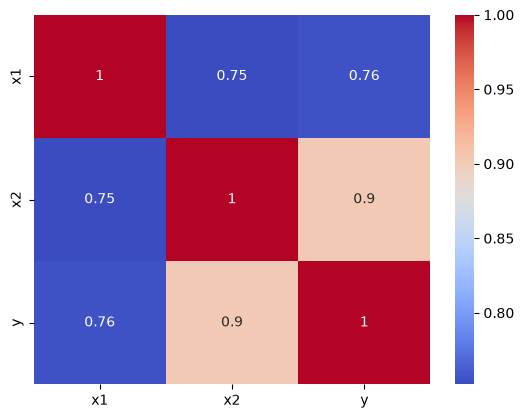

In [18]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm');

In [9]:
corr_d = df.corr()
corr_d

,x1,x2,y
x1,1.000000,0.751919,0.755482
x2,0.751919,1.000000,0.902382
y,0.755482,0.902382,1.000000


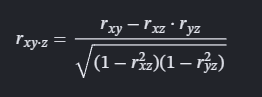

In [10]:
rx1 = (corr_d['x1']['y'] - corr_d['x1']['x2'] * corr_d['x2']['y']) / np.sqrt((1 - corr_d['x1']['x2'] ** 2) * ((1 - corr_d['x2']['y'] ** 2)))
rx2 = (corr_d['x2']['y'] - corr_d['x1']['x2'] * corr_d['x1']['y']) / np.sqrt((1 - corr_d['x2']['x1'] ** 2) * ((1 - corr_d['x1']['y'] ** 2)))

In [43]:
print(rx1, rx2) #Частные коэффициенты корреляции

0.2709061251741632 0.7740253895164297


Проверка по t-стьюденту парного коэффициента корреляции
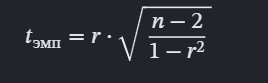

Проверка по t-стьюденту частного коэффициента корреляции
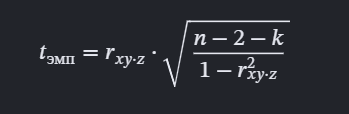

In [30]:
def t_check(r, n, t_krit):
    try:
        t_emp = r * np.sqrt((n - 2) / (1 - r ** 2))
        if t_emp > abs(t_krit):
            return str(round(r, 2)) + '*'
        else:
            return str(round(r, 2))
    except:
        return 1
    

In [25]:
znach_corr_d = corr_d.map(lambda r: t_check(r, n=14, t_krit=2.179))

In [28]:
t_check(rx1, 11, 2.201)

'0.2709061251741632'

In [29]:
t_check(rx2, 11, 2.201)

'0.7740253895164297*'

In [26]:
znach_corr_d

,x1,x2,y
x1,1,0.7519193960369405*,0.7554820776486337*
x2,0.7519193960369405*,1,0.9023815217981916*
y,0.7554820776486337*,0.9023815217981916*,1


In [11]:
print(corr_d['y'].drop('y'))
print()
print('Частная корреляция')
print(pd.Series(index=['x1', 'x2'], data=[rx1, rx2]))

x1    0.755482
x2    0.902382
Name: y, dtype: float64

Частная корреляция
x1    0.270906
x2    0.774025
dtype: float64


In [14]:
import scipy.stats as stats
import statsmodels.api as sm

In [17]:

# Выделяем целевую переменную и признаки
y = df['y']
X = df[['x1', 'x2']]

# Добавляем константу (интерцепт)
X = sm.add_constant(X)

# Создаем и обучаем модель
model = sm.OLS(y, X)
results = model.fit()

# Выводим отчет
print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.828
Model:                            OLS   Adj. R-squared:                  0.797
Method:                 Least Squares   F-statistic:                     26.46
Date:                Tue, 29 Sep 2026   Prob (F-statistic):           6.26e-05
Time:                        18:39:04   Log-Likelihood:                -1.6380
No. Observations:                  14   AIC:                             9.276
Df Residuals:                      11   BIC:                             11.19
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1699      0.206      0.823      0.4